# How the Dixie Fire Spread: Reading Wildfire Propagation from Satellites and Re-Running It with a Simple Model

The Dixie Fire started on 13 July 2021 in the Feather River Canyon above Cresta Dam and burned about 963,000 acres
(close to 3,900 km²) over more than three months before it was contained on 25 October, the largest single-ignition
wildfire in California's record. This notebook asks two questions about it:

1. **How did it spread?** From the day each 500 m pixel burned (MODIS burned area, MCD64A1) I build an
   *arrival-time map* and turn it into a spread-rate and spread-direction map. Then I check, pixel by pixel,
   how often the fire ran **with the wind** and how often it ran **uphill**, and how spread rate changed with wind,
   fire danger (ERC) and dryness of the air (VPD) from gridMET daily weather.
2. **Can a simple model re-create it?** I fit a small, transparent spread-rate equation to the observed head-fire runs
   and use it in a grid-based fire-spread simulator (a shortest-travel-time method with elliptical, wind-driven fire
   shapes and day-by-day weather). The simulated fire is compared with the real one, day by day.

**Where this fits.** Several projects already turn satellite data into fire progression, for example the Global Fire
Atlas and *firedpy* (daily fire events from MCD64A1) and *GOFER* (hourly progression of California fires from GOES).
Discussions around *firedpy* also pointed out that MCD64A1 burn dates come with an uncertainty layer that is rarely
used. Building on that, what I add here is (a) a pixel-level check of wind versus slope alignment with **Monte Carlo
uncertainty from the burn-date uncertainty layer**, and (b) a **data-calibrated spread simulator** that is fitted to
the fire itself and tested against it, all in one notebook that runs on any California fire by changing a few settings.

> This is a learning and exploration tool, not an operational fire model: it leaves out spotting, night-time slow-down,
> fuel moisture changes within a day and, importantly, firefighting.

## 1. Setup

Downloads from Earth Engine are small (a few grids) and are saved to `outputs/wildfire_dixie/`, so re-runs are quick.

In [1]:
import os, math, heapq, warnings
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
ee.Initialize(project="YOUR GEE USERNAME")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


## 2. The fire and the settings

Everything specific to the Dixie Fire is in this cell. To study another California fire, change the box, dates and
ignition point (and the folder names, so saved results are not mixed up).

In [2]:
FIRE_NAME = "Dixie Fire (2021)"
FIG_DIR, OUT_DIR = "figures/wildfire_dixie", "outputs/wildfire_dixie"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

BBOX = [-121.70, 39.75, -120.30, 40.75]      # west, south, east, north - large enough to hold the whole fire
START, END = "2021-07-13", "2021-10-25"      # ignition and full containment dates (CAL FIRE)

# Ignition point from CAL FIRE (above Cresta Dam). The Fly Fire started on 22 July north of Keddie and merged into the
# Dixie Fire on 24 July, so I add it as a second ignition (its location here is approximate).
IGNITIONS = [("Dixie", -121.3894, 39.8713, "2021-07-13"),
             ("Fly",   -120.96,  40.02,   "2021-07-22")]

RES = 0.005            # fire grid size in degrees (~500 m, like MODIS burned area)
WX_RES = 0.04          # weather grid size (gridMET is ~4 km)
MAX_ROS = 20.0         # cap on spread rate (km/day) to avoid unrealistic values
HEAD_ANGLE = 45        # a pixel counts as a "head fire" run if it spread within this many degrees of downwind
N_MONTE_CARLO = 30     # how many times to jitter the burn dates within their stated uncertainty
CHECK_DAYS = [3, 7, 14, 21, 30, 45, 60]      # days after ignition when simulated and real fires are compared
SCALES = [0.25, 0.5, 1.0, 2.0, 4.0]          # simulator calibration: multipliers on spread rate to start from

west, south, east, north = BBOX
region = ee.Geometry.Rectangle(BBOX)
start_date, end_date = pd.Timestamp(START), pd.Timestamp(END)
n_days = (end_date - start_date).days + 1

## 3. Data from Earth Engine

**Fire grid (~500 m):** burn day and burn-date uncertainty (MODIS MCD64A1), elevation (NASADEM, averaged to 500 m) and
pre-fire greenness (MODIS NDVI, June 2021).
**Weather grid (~4 km):** daily wind speed and direction, Energy Release Component (ERC, a fire-danger index) and vapour
pressure deficit (VPD, how dry the air is) from gridMET.

In [5]:
import ee
import os
import math
import numpy as np
import pandas as pd

FIRE_NPZ, WX_NPZ = f"{OUT_DIR}/fire_grid.npz", f"{OUT_DIR}/weather_grid.npz"

def grid_transform(res):
    return [res, 0, west, 0, -res, north]

if os.path.exists(FIRE_NPZ):
    fire = dict(np.load(FIRE_NPZ))
else:
    burned = ee.ImageCollection("MODIS/061/MCD64A1").filterDate(f"{start_date:%Y-%m}-01", end_date + pd.offsets.MonthEnd(1))
    burn_day = burned.select("BurnDate").max().rename("burn_doy")            # day of year the pixel burned (0 = not burned)
    uncertainty = burned.select("Uncertainty").max().rename("uncertainty")   # +/- days
    
    dem = ee.Image("NASA/NASADEM_HGT/001").select("elevation")
    # NASADEM also needs a default projection before reduceResolution
    dem_proj = dem.projection()
    elevation = dem.setDefaultProjection(dem_proj).reduceResolution(ee.Reducer.mean(), maxPixels=1024).rename("elevation")
    
    # MODIS NDVI processing - fixed to retain projection before reduceResolution
    modis_ndvi = ee.ImageCollection("MODIS/061/MOD13Q1").filterDate("2021-06-01", "2021-07-01").select("NDVI")
    modis_proj = modis_ndvi.first().projection()
    
    ndvi = (modis_ndvi.mean()
              .multiply(0.0001)
              .setDefaultProjection(modis_proj)  # <--- Fix applied here
              .reduceResolution(ee.Reducer.mean(), maxPixels=64)
              .rename("ndvi"))
              
    stack = (ee.Image.cat(burn_day, uncertainty, elevation, ndvi, ee.Image.pixelLonLat())
               .reproject(crs="EPSG:4326", crsTransform=grid_transform(RES)))
               
    props = stack.sampleRectangle(region=region, defaultValue=0).getInfo()["properties"]
    fire = {k: np.array(v, dtype=float) for k, v in props.items()}
    np.savez(FIRE_NPZ, **fire)

if os.path.exists(WX_NPZ):
    wx = dict(np.load(WX_NPZ))
else:
    gridmet = ee.ImageCollection("IDAHO_EPSCOR/GRIDMET").filterDate(START, end_date + pd.Timedelta(days=1))
    wx = {}
    for var in ["vs", "th", "erc", "vpd"]:          # wind speed (m/s), wind FROM direction (deg), ERC, VPD (kPa)
        img = gridmet.select(var).toBands().reproject(crs="EPSG:4326", crsTransform=grid_transform(WX_RES))
        props = img.sampleRectangle(region=region, defaultValue=0).getInfo()["properties"]
        keys = sorted(props)                          # band names start with the date, so sorting puts days in order
        wx[var] = np.stack([np.array(props[k], dtype=float) for k in keys])
        print(f"{var}: {wx[var].shape[0]} days")
    np.savez(WX_NPZ, **wx)

lon, lat = fire["longitude"], fire["latitude"]
lat_c = float(np.mean(lat))
dx = RES * 111_320 * math.cos(math.radians(lat_c))     
dy = RES * 110_540                                    
cell_km2 = dx * dy / 1e6

start_doy = start_date.dayofyear
T_obs = np.where((fire["burn_doy"] >= start_doy) & (fire["burn_doy"] <= end_date.dayofyear),
                 fire["burn_doy"] - start_doy + 0.5, np.nan)
uncert = np.where(np.isfinite(T_obs), fire["uncertainty"], np.nan)
elev, ndvi = fire["elevation"], fire["ndvi"]

ci = np.clip(((north - lat) / WX_RES).astype(int), 0, wx["vs"].shape[1] - 1)
cj = np.clip(((lon - west) / WX_RES).astype(int), 0, wx["vs"].shape[2] - 1)
n_wx_days = wx["vs"].shape[0]
downwind = (wx["th"] + 180) % 360                        
print(f"Fire grid {T_obs.shape}, burned cells: {np.isfinite(T_obs).sum():,} "
      f"(≈ {np.isfinite(T_obs).sum() * cell_km2:,.0f} km²) | weather days: {n_wx_days}")

vs: 105 days
th: 105 days
erc: 105 days
vpd: 105 days
Fire grid (200, 280), burned cells: 15,345 (≈ 3,603 km²) | weather days: 105


## 4. A small toolbox

All the calculations, kept in one place: smoothing, spread rate and direction from the arrival-time map, terrain,
the wind-driven ellipse, the fire-spread simulator and the comparison score.

In [6]:
def nan_smooth(a, passes=1):
    out = a.copy()
    for _ in range(passes):
        p = np.pad(out, 1, constant_values=np.nan)
        stack = np.stack([p[i:i + a.shape[0], j:j + a.shape[1]] for i in range(3) for j in range(3)])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)      # cells with no burned neighbours at all
            out = np.where(np.isfinite(a), np.nanmean(stack, axis=0), np.nan)
    return out

def azimuth_of_gradient(field):
    # Direction (degrees clockwise from north) in which 'field' increases, and how fast (units per metre)
    d_row, d_col = np.gradient(field, dy, dx)
    g_north, g_east = -d_row, d_col                  # rows go southwards
    return (np.degrees(np.arctan2(g_east, g_north)) % 360), np.hypot(g_east, g_north)

def spread_from_arrival(T):
    # Fire moves the way arrival time increases; speed is 1 / (how quickly arrival time changes with distance)
    az, g = azimuth_of_gradient(nan_smooth(T))
    with np.errstate(divide="ignore", invalid="ignore"):
        ros = np.where(g > 0, 1 / (g * 1000), np.nan)      # km/day
    return np.clip(ros, 0, MAX_ROS), np.where(g > 0, az, np.nan)

def angle_diff(a, b):
    # Smallest angle between two directions (0-180 degrees)
    return np.abs((a - b + 180) % 360 - 180)

def ellipse_eccentricity(wind_ms):
    # Anderson (1983) length-to-breadth ratio of a wind-driven fire (wind in mph), then eccentricity of the ellipse
    mph = wind_ms * 2.237
    lb = np.clip(0.936 * np.exp(0.2566 * mph) + 0.461 * np.exp(-0.1548 * mph) - 0.397, 1.0, 8.0)
    return np.sqrt(lb ** 2 - 1) / lb

STEPS = [(di, dj) for di in (-1, 0, 1) for dj in (-1, 0, 1) if (di, dj) != (0, 0)]
STEP_DIST = {s: math.hypot(s[0] * dy, s[1] * dx) for s in STEPS}
STEP_AZ = {s: math.degrees(math.atan2(s[1] * dx, -s[0] * dy)) % 360 for s in STEPS}

def simulate(coef, scale, burnable, ignitions_rc, max_days):
    # Shortest-travel-time fire spread on the grid (a Dijkstra search). From each burning cell the fire reaches its
    # 8 neighbours at a speed set by the fitted equation, the day's weather and the wind ellipse.
    b0, bU, bE, bV, bN, bS = coef
    T = np.full(burnable.shape, np.inf)
    heap = []
    for r, c_, t0 in ignitions_rc:
        T[r, c_] = t0
        heapq.heappush(heap, (t0, r, c_))
    nr, nc = burnable.shape
    while heap:
        t, r, c_ = heapq.heappop(heap)
        if t > T[r, c_] or t > max_days:
            continue
        d = min(int(t), n_wx_days - 1)
        a, b = ci[r, c_], cj[r, c_]
        U = wx["vs"][d, a, b]
        base = b0 + bU * U + bE * wx["erc"][d, a, b] + bV * wx["vpd"][d, a, b] + bN * ndvi[r, c_]
        dw, ecc = downwind[d, a, b], ECC[d, a, b]
        ts, up = TAN_SLOPE[r, c_], UPSLOPE[r, c_]
        for s in STEPS:
            rr, cc = r + s[0], c_ + s[1]
            if rr < 0 or cc < 0 or rr >= nr or cc >= nc or not burnable[rr, cc]:
                continue
            az = STEP_AZ[s]
            lin = min(max(base + bS * ts * math.cos(math.radians(az - up)), -10.0), 5.0)
            ell = (1 - ecc) / (1 - ecc * math.cos(math.radians(az - dw)))
            ros = min(scale * math.exp(lin) * ell, MAX_ROS)            # km/day
            nt = t + STEP_DIST[s] / (ros * 1000)
            if nt < T[rr, cc]:
                T[rr, cc] = nt
                heapq.heappush(heap, (nt, rr, cc))
    T[T > max_days] = np.inf
    return T

def sorensen(a, b):
    # Overlap score between two burned areas: 1 = identical, 0 = no overlap
    return 2 * np.sum(a & b) / max(np.sum(a) + np.sum(b), 1)

# Terrain (from the 500 m elevation) and the wind ellipse for every weather cell and day
slope_az, slope_grad = azimuth_of_gradient(nan_smooth(np.where(elev > 0, elev, np.nan)))
TAN_SLOPE = np.nan_to_num(slope_grad)
UPSLOPE = np.nan_to_num(slope_az)
ECC = ellipse_eccentricity(wx["vs"])
print("Toolbox ready.")

Toolbox ready.


## 5. How the real fire grew

Daily burned area from the burn-day map, the biggest growth days and the weather over the fire on those days.

In [7]:
burned_mask = np.isfinite(T_obs)
day_idx = np.where(burned_mask, np.floor(T_obs).astype(int), -1)
daily_km2 = pd.Series(np.bincount(day_idx[burned_mask], minlength=n_days)[:n_days] * cell_km2,
                      index=pd.date_range(start_date, periods=n_days), name="burned_km2")
growth = daily_km2.to_frame()
growth["cumulative_km2"] = growth["burned_km2"].cumsum()

def fire_weather(day):
    # Average weather over the cells that burned on this day
    cells = day_idx == day
    if not cells.any() or day >= n_wx_days:
        return pd.Series(dtype=float)
    a, b = ci[cells], cj[cells]
    ang = np.radians(wx["th"][day, a, b])
    mean_from = math.degrees(math.atan2(np.sin(ang).mean(), np.cos(ang).mean())) % 360
    return pd.Series({"wind_ms": wx["vs"][day, a, b].mean(), "wind_from_deg": mean_from,
                      "erc": wx["erc"][day, a, b].mean(), "vpd_kpa": wx["vpd"][day, a, b].mean()})

big_days = growth["burned_km2"].nlargest(8)
runs = pd.DataFrame({d.strftime("%Y-%m-%d"): pd.concat([pd.Series({"burned_km2": v}), fire_weather((d - start_date).days)])
                     for d, v in big_days.items()}).T
growth.round(2).to_csv(f"{OUT_DIR}/daily_growth.csv")
runs.round(2).to_csv(f"{OUT_DIR}/biggest_growth_days.csv")
print(f"Total mapped burned area: {growth['cumulative_km2'].iloc[-1]:,.0f} km²")
runs.round(1)

Total mapped burned area: 3,603 km²


C:\Users\moham\AppData\Local\Temp\ipykernel_144812\2920698336.py:2: RuntimeWarning: invalid value encountered in cast
  day_idx = np.where(burned_mask, np.floor(T_obs).astype(int), -1)


,burned_km2,wind_ms,wind_from_deg,erc,vpd_kpa
2021-08-06,292.8,2.1,345.6,91.5,1.8
2021-08-05,168.8,3.9,223.0,92.0,1.8
2021-08-31,167.9,3.7,259.8,94.4,1.9
2021-08-07,164.6,3.2,218.4,93.0,2.1
2021-08-18,161.1,5.3,17.1,86.7,1.0
2021-08-17,129.4,4.7,291.1,88.9,1.3
2021-07-20,126.3,3.7,187.1,91.9,2.2
2021-07-25,109.2,3.0,255.6,94.0,2.5


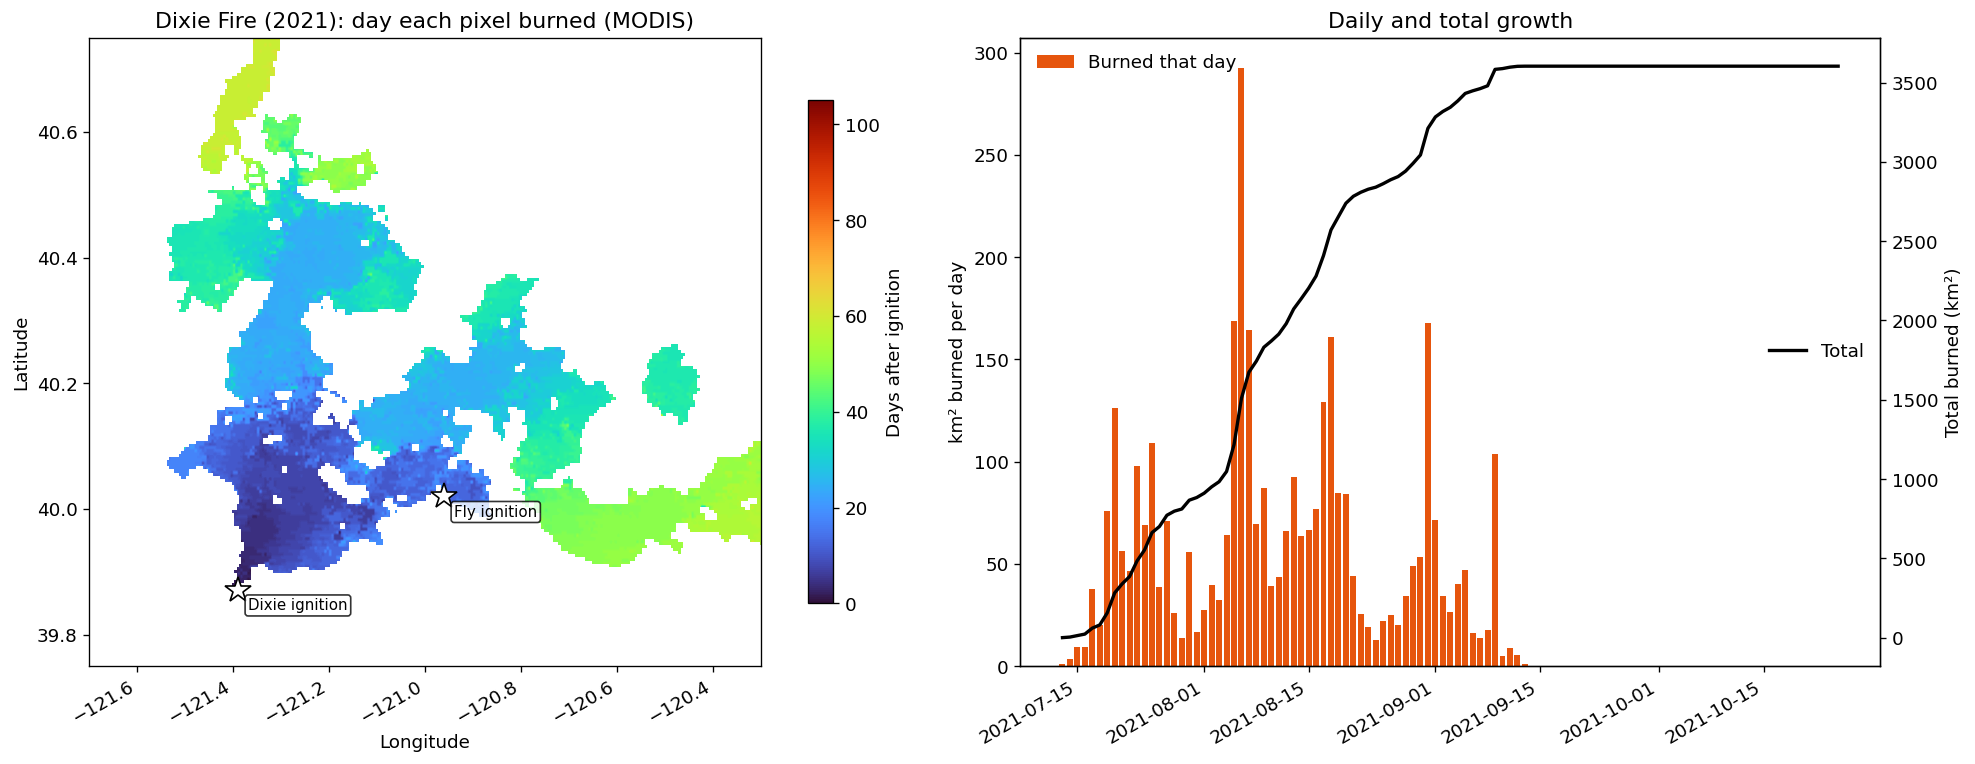

In [8]:
extent = [west, east, south, north]
aspect = 1 / math.cos(math.radians(lat_c))
ign_rc = []
for name, x, y, d in IGNITIONS:
    r, c_ = np.unravel_index(np.argmin((lon - x) ** 2 + (lat - y) ** 2), lon.shape)
    ign_rc.append((r, c_, (pd.Timestamp(d) - start_date).days + 0.5))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax1.imshow(T_obs, extent=extent, cmap="turbo", vmin=0, vmax=n_days)
for (name, x, y, d) in IGNITIONS:
    ax1.plot(x, y, "*", color="white", mec="black", ms=16)
    ax1.annotate(f"{name} ignition", (x, y), xytext=(6, -12), textcoords="offset points", fontsize=9,
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
ax1.set(title=f"{FIRE_NAME}: day each pixel burned (MODIS)", xlabel="Longitude", ylabel="Latitude")
ax1.set_aspect(aspect)
fig.colorbar(im, ax=ax1, label="Days after ignition", shrink=0.8)

ax2.bar(growth.index, growth["burned_km2"], color="#e6550d", label="Burned that day")
ax2b = ax2.twinx()
ax2b.plot(growth.index, growth["cumulative_km2"], color="black", lw=2, label="Total")
ax2.set(ylabel="km² burned per day", title="Daily and total growth")
ax2b.set_ylabel("Total burned (km²)")
ax2.legend(loc="upper left", frameon=False); ax2b.legend(loc="center right", frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_arrival_time_and_growth.png"); plt.show()

## 6. Which way did it run: with the wind or uphill?

For every burned pixel I compare the direction the fire moved with the downwind direction and the uphill direction on
the day it burned. A fire purely pushed by wind would line up with downwind; a terrain-driven fire with uphill.

MCD64A1 gives an uncertainty of a few days for each burn date, so I repeat the analysis `N_MONTE_CARLO` times with the
burn dates randomly shifted within that uncertainty, and report the spread of the results.

In [9]:
def alignment_stats(T):
    ros, az = spread_from_arrival(T)
    ok = np.isfinite(az) & np.isfinite(T)
    d = np.clip(np.floor(T[ok]).astype(int), 0, n_wx_days - 1)
    dw = downwind[d, ci[ok], cj[ok]]
    with_wind = angle_diff(az[ok], dw)
    uphill = angle_diff(az[ok], UPSLOPE[ok])
    steep = TAN_SLOPE[ok] > math.tan(math.radians(10))
    return {"Share running with the wind (±45°)": np.mean(with_wind <= 45),
            "Share running against the wind (backing, ±45°)": np.mean(with_wind >= 135),
            "Share running uphill on slopes > 10° (±45°)": np.mean(uphill[steep] <= 45),
            "Median spread rate (km/day)": np.nanmedian(ros[ok]),
            "90th percentile spread rate (km/day)": np.nanpercentile(ros[ok], 90)}

observed_stats = alignment_stats(T_obs)
rng = np.random.default_rng(1)
mc = pd.DataFrame([alignment_stats(T_obs + rng.uniform(-1, 1, T_obs.shape) * np.nan_to_num(uncert))
                   for _ in range(N_MONTE_CARLO)])
alignment = pd.DataFrame({"Burn dates as reported": pd.Series(observed_stats),
                          "Monte Carlo 5%": mc.quantile(0.05), "Monte Carlo 95%": mc.quantile(0.95)})
alignment.round(3).to_csv(f"{OUT_DIR}/spread_alignment.csv")
print("A random direction would line up with the wind (±45°) 25% of the time; higher means the wind was steering the fire.")
alignment.round(3)

A random direction would line up with the wind (±45°) 25% of the time; higher means the wind was steering the fire.


,Burn dates as reported,Monte Carlo 5%,Monte Carlo 95%
Share running with the wind (±45°),0.271,0.258,0.267
"Share running against the wind (backing, ±45°)",0.205,0.227,0.238
Share running uphill on slopes > 10° (±45°),0.246,0.237,0.281
Median spread rate (km/day),1.073,0.595,0.613
90th percentile spread rate (km/day),3.569,1.676,1.768


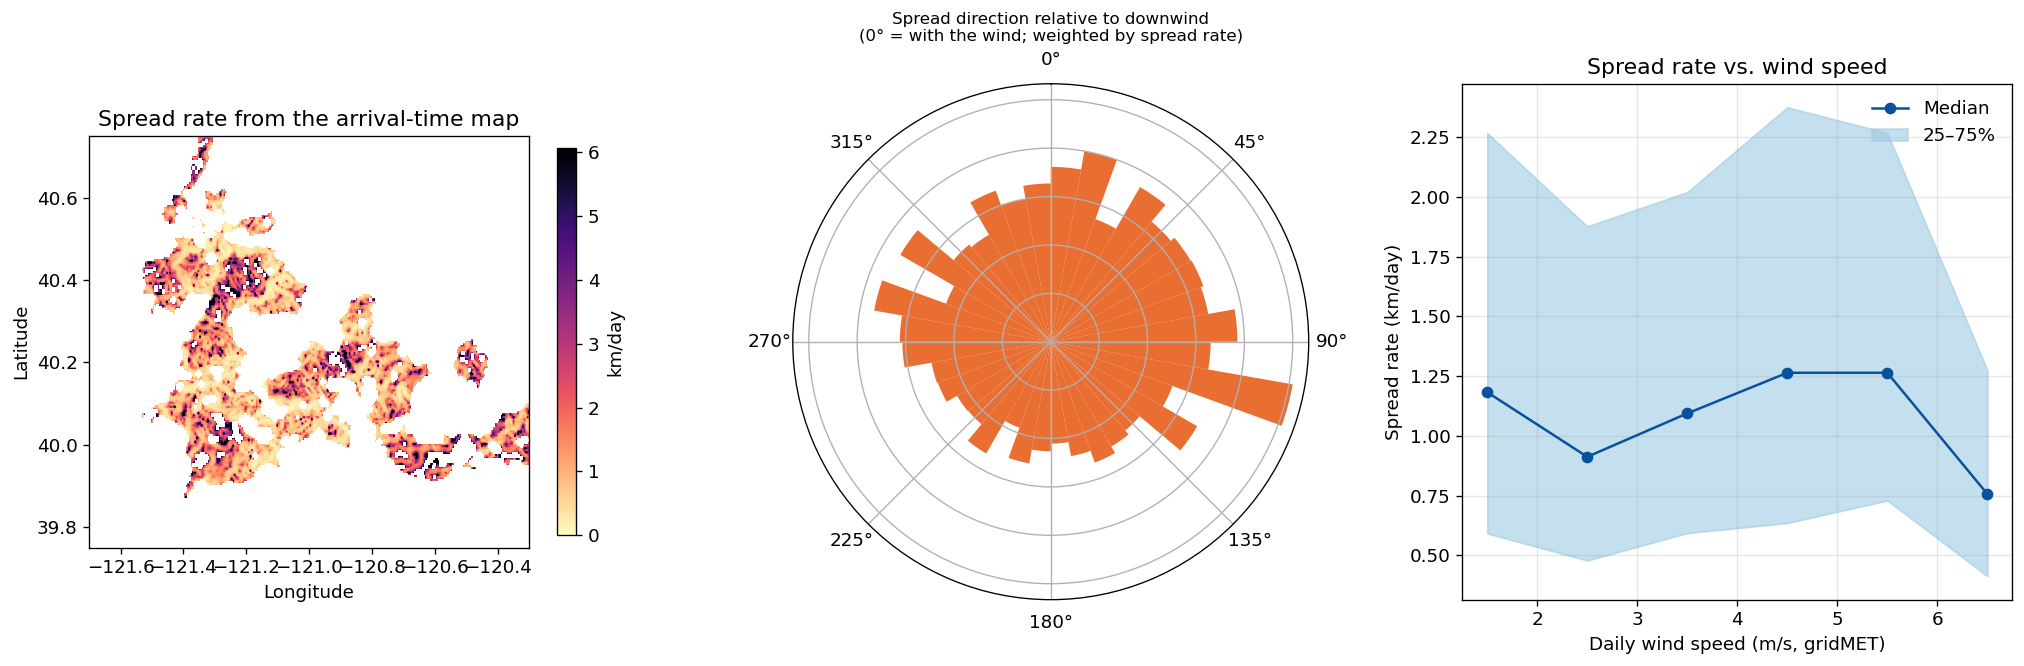

Rank correlation of spread rate with each driver:
wind_ms        0.060
erc            0.115
vpd_kpa       -0.121
ndvi          -0.068
slope_along   -0.031


In [10]:
ros_obs, az_obs = spread_from_arrival(T_obs)
ok = np.isfinite(az_obs) & burned_mask
d_ok = np.clip(np.floor(T_obs[ok]).astype(int), 0, n_wx_days - 1)
drivers = pd.DataFrame({
    "ros_km_day": ros_obs[ok],
    "spread_az": az_obs[ok],
    "wind_ms": wx["vs"][d_ok, ci[ok], cj[ok]],
    "downwind_az": downwind[d_ok, ci[ok], cj[ok]],
    "erc": wx["erc"][d_ok, ci[ok], cj[ok]],
    "vpd_kpa": wx["vpd"][d_ok, ci[ok], cj[ok]],
    "ndvi": ndvi[ok],
    "tan_slope": TAN_SLOPE[ok],
    "upslope_az": UPSLOPE[ok],
    "day": d_ok,
})
drivers["angle_to_downwind"] = angle_diff(drivers["spread_az"], drivers["downwind_az"])
drivers["slope_along"] = drivers["tan_slope"] * np.cos(np.radians(drivers["spread_az"] - drivers["upslope_az"]))
drivers.round(4).to_csv(f"{OUT_DIR}/pixel_drivers.csv", index=False)

fig = plt.figure(figsize=(17, 5.5))
ax1 = fig.add_subplot(1, 3, 1)
im = ax1.imshow(ros_obs, extent=extent, cmap="magma_r", vmin=0, vmax=np.nanpercentile(ros_obs, 95))
ax1.set(title="Spread rate from the arrival-time map", xlabel="Longitude", ylabel="Latitude"); ax1.set_aspect(aspect)
fig.colorbar(im, ax=ax1, label="km/day", shrink=0.75)

ax2 = fig.add_subplot(1, 3, 2, projection="polar")
rel = np.radians((drivers["spread_az"] - drivers["downwind_az"]) % 360)
ax2.hist(rel, bins=36, color="#e6550d", alpha=0.85, weights=drivers["ros_km_day"])
ax2.set_theta_zero_location("N"); ax2.set_theta_direction(-1); ax2.set_yticklabels([])
ax2.set_title("Spread direction relative to downwind\n(0° = with the wind; weighted by spread rate)", fontsize=10)

ax3 = fig.add_subplot(1, 3, 3)
bins = pd.cut(drivers["wind_ms"], bins=np.arange(0, drivers["wind_ms"].max() + 1, 1))
grp = drivers.groupby(bins, observed=True)["ros_km_day"]
mid = [iv.mid for iv in grp.median().index]
ax3.plot(mid, grp.median(), "o-", color="#08519c", label="Median")
ax3.fill_between(mid, grp.quantile(0.25), grp.quantile(0.75), color="#9ecae1", alpha=0.6, label="25–75%")
ax3.set(xlabel="Daily wind speed (m/s, gridMET)", ylabel="Spread rate (km/day)", title="Spread rate vs. wind speed")
ax3.legend(frameon=False); ax3.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_spread_rate_and_direction.png"); plt.show()

corr = drivers[["wind_ms", "erc", "vpd_kpa", "ndvi", "slope_along"]].corrwith(drivers["ros_km_day"], method="spearman")
print("Rank correlation of spread rate with each driver:"); print(corr.round(3).to_string())

## 7. A spread-rate equation fitted to the fire itself

I keep the pixels where the fire was running roughly with the wind (head-fire runs) and fit:

log(spread rate) = b0 + bU·wind + bE·ERC + bV·VPD + bN·NDVI + bS·(slope along the spread direction)

A log scale is used because spread rate varies over orders of magnitude. The coefficients tell how much each factor
speeds the fire up, and they become the engine of the simulator in the next section.

In [11]:
head = drivers[(drivers["angle_to_downwind"] <= HEAD_ANGLE) & (drivers["ros_km_day"] > 0.05)].dropna()
X = np.column_stack([np.ones(len(head)), head["wind_ms"], head["erc"], head["vpd_kpa"], head["ndvi"], head["slope_along"]])
y = np.log(head["ros_km_day"].values)
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
pred = X @ coef
r2 = 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)

terms = ["Intercept", "Wind speed (per m/s)", "ERC (per unit)", "VPD (per kPa)", "NDVI (per unit)", "Slope along spread (per unit tan)"]
coef_table = pd.DataFrame({"Coefficient": coef, "Effect on spread rate": [""] + [f"×{math.exp(b):.3f}" for b in coef[1:]]},
                          index=terms)
coef_table.round(4).to_csv(f"{OUT_DIR}/spread_equation.csv")
print(f"Head-fire pixels used: {len(head):,} | R² on log scale: {r2:.3f}")
print("'×1.15 per m/s' would mean each extra m/s of wind makes the fire 15% faster, other things equal.")
coef_table.round(4)

Head-fire pixels used: 3,419 | R² on log scale: 0.038
'×1.15 per m/s' would mean each extra m/s of wind makes the fire 15% faster, other things equal.


,Coefficient,Effect on spread rate
Intercept,-0.5887,
Wind speed (per m/s),-0.0177,×0.982
ERC (per unit),0.0210,×1.021
VPD (per kPa),-0.3743,×0.688
NDVI (per unit),-0.7098,×0.492
Slope along spread (per unit tan),-0.2538,×0.776


## 8. Re-running the fire with the simulator

The simulator starts from the ignition points on their real start days and lets the fire travel across the grid
using the fitted equation, the daily weather and the wind ellipse. Cells that were not green before the fire
(NDVI < 0.15: rock, water, bare ground) cannot burn.

Because the equation was fitted on pixel-level speeds, the overall pace may still be off (firefighting, spotting and
night-time slow-down are not in the model). So I try a few overall speed multipliers (`SCALES`, extended automatically if the best one is at the edge) and keep the
one that best matches the real fire's area over time. That single number is the only thing calibrated on the overall result.

In [12]:
burnable = (ndvi > 0.15) & (elev > 0)
max_days = n_days
results = {}
def try_scale(s):
    T_try = simulate(coef, s, burnable, ign_rc, max_days)
    results[s] = (np.mean([sorensen(T_obs <= k, T_try <= k) for k in CHECK_DAYS]), T_try)
    print(f"speed multiplier {s:>7.3g}: mean overlap score {results[s][0]:.3f}")

for s in SCALES:
    try_scale(s)
# If the best multiplier is at the edge of the list, keep going in that direction until the score stops improving
for _ in range(6):
    best_scale = max(results, key=lambda s: results[s][0])
    if best_scale == max(results):
        try_scale(best_scale * 2)
    elif best_scale == min(results):
        try_scale(best_scale / 2)
    else:
        break
best_scale = max(results, key=lambda s: results[s][0])
T_sim = results[best_scale][1]
print(f"Best multiplier: {best_scale}")

evaluation = pd.DataFrame({
    "Day": CHECK_DAYS + [n_days],
    "Real burned area (km²)": [np.sum(T_obs <= k) * cell_km2 for k in CHECK_DAYS + [n_days]],
    "Simulated burned area (km²)": [np.sum(T_sim <= k) * cell_km2 for k in CHECK_DAYS + [n_days]],
    "Overlap score (Sørensen)": [sorensen(T_obs <= k, T_sim <= k) for k in CHECK_DAYS + [n_days]],
}).set_index("Day")
both = np.isfinite(T_obs) & np.isfinite(T_sim)
rho = stats.spearmanr(T_obs[both], T_sim[both]).correlation if both.sum() > 10 else np.nan
mae = np.mean(np.abs(T_obs[both] - T_sim[both])) if both.any() else np.nan
evaluation.round(3).to_csv(f"{OUT_DIR}/simulation_evaluation.csv")
print(f"Where both burned: arrival-day rank correlation {rho:.2f}, mean timing error {mae:.1f} days")
evaluation.round(2)

speed multiplier    0.25: mean overlap score 0.007
speed multiplier     0.5: mean overlap score 0.016
speed multiplier       1: mean overlap score 0.037
speed multiplier       2: mean overlap score 0.134
speed multiplier       4: mean overlap score 0.390
speed multiplier       8: mean overlap score 0.450
speed multiplier      16: mean overlap score 0.312
Best multiplier: 8.0
Where both burned: arrival-day rank correlation 0.73, mean timing error 12.4 days


,Real burned area (km²),Simulated burned area (km²),Overlap score (Sørensen)
Day,,,
3,13.85,13.85,0.37
7,156.84,149.33,0.55
14,701.33,875.55,0.57
21,951.39,3142.27,0.40
30,1914.05,7457.10,0.41
45,2887.04,10983.02,0.42
60,3587.67,12762.07,0.44
105,3602.93,12834.38,0.44


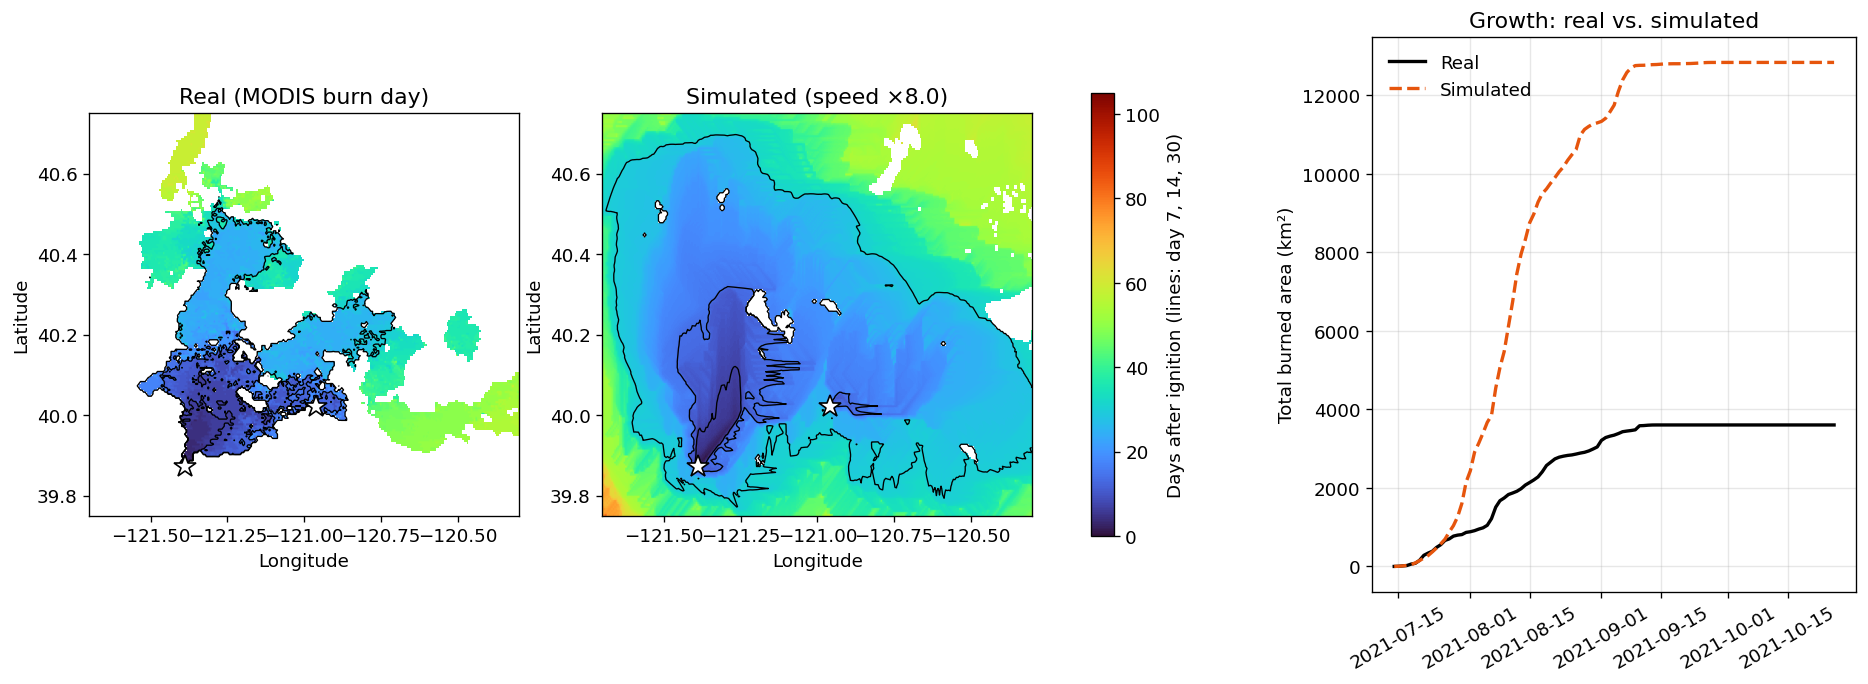

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
vmax = n_days
for ax, data, title in [(axes[0], T_obs, "Real (MODIS burn day)"),
                        (axes[1], np.where(np.isfinite(T_sim), T_sim, np.nan), f"Simulated (speed ×{best_scale})")]:
    im = ax.imshow(data, extent=extent, cmap="turbo", vmin=0, vmax=vmax)
    ax.contour(np.where(np.isfinite(data), data, vmax + 1), levels=[7, 14, 30], extent=extent, origin="upper",
               colors="black", linewidths=0.8)
    for (_, x, y, _) in IGNITIONS:
        ax.plot(x, y, "*", color="white", mec="black", ms=14)
    ax.set_title(title); ax.set_aspect(aspect); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.colorbar(im, ax=axes[:2], label="Days after ignition (lines: day 7, 14, 30)", shrink=0.8)

days_axis = np.arange(1, n_days + 1)
axes[2].plot(start_date + pd.to_timedelta(days_axis, "D"), [np.sum(T_obs <= k) * cell_km2 for k in days_axis],
             color="black", lw=2, label="Real")
axes[2].plot(start_date + pd.to_timedelta(days_axis, "D"), [np.sum(T_sim <= k) * cell_km2 for k in days_axis],
             color="#e6550d", lw=2, ls="--", label="Simulated")
axes[2].set(ylabel="Total burned area (km²)", title="Growth: real vs. simulated"); axes[2].legend(frameon=False)
axes[2].grid(alpha=0.3); axes[2].tick_params(axis="x", rotation=30)
fig.savefig(f"{FIG_DIR}/03_real_vs_simulated.png", bbox_inches="tight"); plt.show()

## 9. Try it yourself: a "what if" run

With the simulator ready, it is easy to ask questions such as: how much less would the fire have grown in its first
two weeks if the wind had been 30% weaker? This changes only the weather fed to the model, not the fitted equation.

In [14]:
WIND_FACTOR = 0.7       # 1.0 = real winds
WHAT_IF_DAYS = 14

saved_vs, saved_ecc = wx["vs"].copy(), ECC.copy()
wx["vs"] = saved_vs * WIND_FACTOR
ECC = ellipse_eccentricity(wx["vs"])
T_whatif = simulate(coef, best_scale, burnable, ign_rc, WHAT_IF_DAYS)
wx["vs"], ECC = saved_vs, saved_ecc                       # put the real winds back

base_area = np.sum(T_sim <= WHAT_IF_DAYS) * cell_km2
what_if_area = np.sum(T_whatif <= WHAT_IF_DAYS) * cell_km2
print(f"Simulated area after {WHAT_IF_DAYS} days: real winds {base_area:,.0f} km² | "
      f"winds ×{WIND_FACTOR} {what_if_area:,.0f} km² ({100 * (what_if_area / base_area - 1):+.0f}%)")

Simulated area after 14 days: real winds 876 km² | winds ×0.7 2,430 km² (+178%)


## 10. Notes

- **Data:** MODIS MCD64A1 v6.1 burned area (Giglio et al. 2018); gridMET daily weather (Abatzoglou 2013); NASADEM;
  MODIS MOD13Q1 NDVI. Fire facts (start, containment, ignition point, Fly Fire) from CAL FIRE incident information.
- **Related work this builds on:** Global Fire Atlas (Andela et al. 2019) and *firedpy* (Earth Lab) for fire events
  and spread from MCD64A1; GOFER (Liu et al. 2024) for hourly progression of California fires from GOES; FEDS
  (Chen et al. 2022) for VIIRS-based fire tracking. GOFER and FEDS perimeters are good references to check this
  notebook's arrival-time map against.
- **Limits:** MCD64A1 records the *day* a 500 m pixel burned, with a stated uncertainty of several days in places; the
  fire's fastest runs (many kilometres in an afternoon) are smoothed out, and spread rates here are daily averages.
  Burnout operations, spot fires and suppression lines all shape the real perimeter but are not in the simulator. The
  ellipse shape follows Anderson (1983); real fire shapes are more irregular.
- **Another fire:** change `FIRE_NAME`, `BBOX`, `START`, `END`, `IGNITIONS` and the folder names in Section 2.
  Good candidates in California with long, multi-day spread: August Complex (2020), Creek (2020), Caldor (2021).